In [1]:
%pip install scikit-learn matplotlib seaborn


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\geeta\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


Dataset shape: (1797, 64)
Labels shape: (1797,)
Digit classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


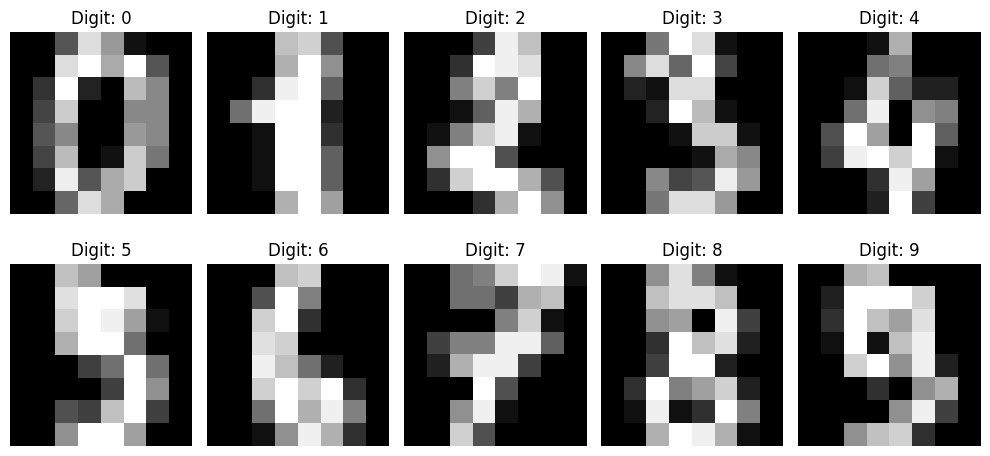

Training samples: 1437
Testing samples: 360

SVM Accuracy: 98.06 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      0.97      0.97        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.95      0.97      0.96        36
           5       0.97      1.00      0.99        37
           6       0.97      1.00      0.99        36
           7       0.95      0.97      0.96        36
           8       1.00      0.94      0.97        35
           9       1.00      0.94      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



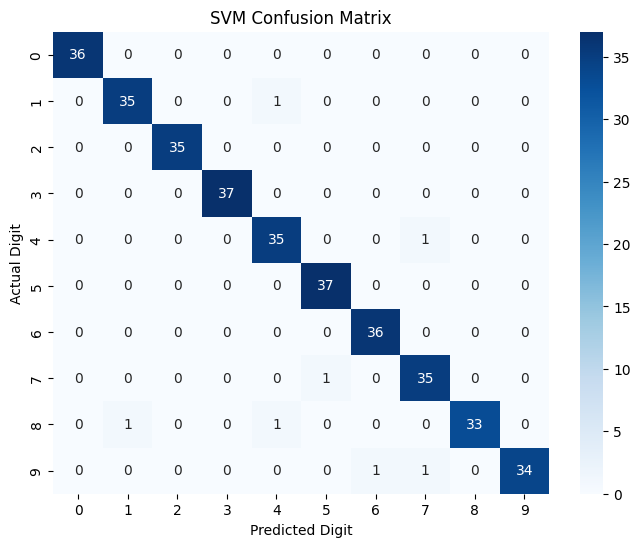

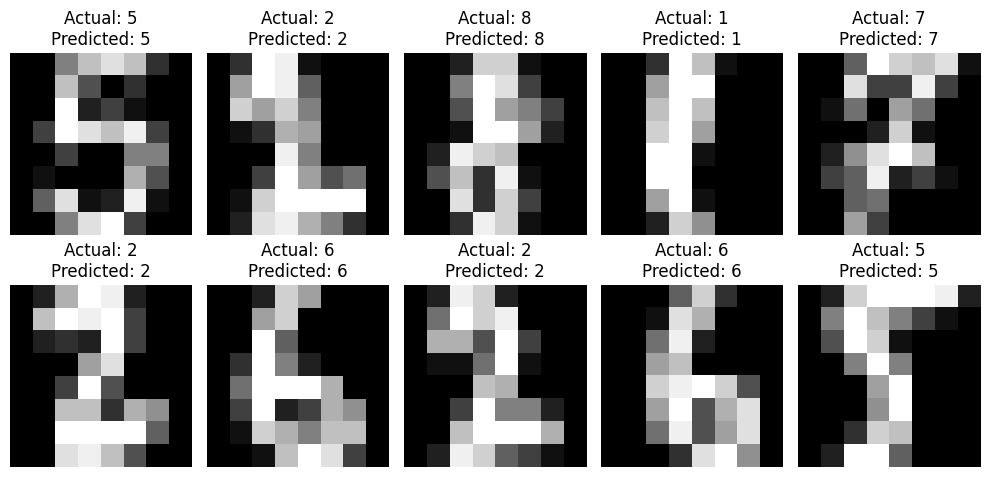

In [2]:
# Step 1: Import libraries
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Step 2: Load dataset
digits = load_digits()
X = digits.data
y = digits.target

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)
print("Digit classes:", sorted(set(y)))

# Step 3: Display sample images
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for ax, image, label in zip(
    axes.ravel(), digits.images[:10], y[:10]
):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Digit: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Step 4: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Step 5: Create and train SVM model
model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10, gamma="scale")
)

model.fit(X_train, y_train)

# Step 6: Make predictions
y_pred = model.predict(X_test)

# Step 7: Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("\nSVM Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Step 8: Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("SVM Confusion Matrix")
plt.show()

# Step 9: Display actual vs predicted digits
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for ax, i in zip(axes.ravel(), range(10)):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray")
    ax.set_title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()